# Dataset analysis

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import os
import zipfile

In [4]:
ZIP_PATH="/content/sample_data/bharatnatya_mudras/mudra.zip"
DATA_DIR="dataset_unzipped"

if not os.path.exists(DATA_DIR):
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(DATA_DIR)
    print("Dataset extracted successfully.")
subfolders = [f.path for f in os.scandir(DATA_DIR) if f.is_dir()]
if len(subfolders) == 1:
    DATA_DIR = subfolders[0]

Dataset extracted successfully.


In [5]:
train_ds=tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.3,
    subset="training",
    seed=42,
    image_size=(128, 128),
    batch_size=32
)

temp_ds=tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.3,
    subset="validation",
    seed=42,
    image_size=(128, 128),
    batch_size=32
)

Found 2000 files belonging to 5 classes.
Using 1400 files for training.
Found 2000 files belonging to 5 classes.
Using 600 files for validation.


In [6]:
class_names=train_ds.class_names
print("Mudras:",class_names)

Mudras: ['Musti', 'Pataka', 'Sikhara', 'Simhamukha', 'Trisula']


In [7]:
half=len(temp_ds) // 2
val_ds=temp_ds.take(half)
test_ds=temp_ds.skip(half)

print(f"Train size: {len(train_ds)}")
print(f"Validation size: {len(val_ds)}")
print(f"Test size: {len(test_ds)}")

Train size: 44
Validation size: 9
Test size: 10


# **Questions**
1. Is the dataset balanced? How might imbalance affect learning?
2. What image characteristics could make mudra recognition difficult?
3. Would increasing image resolution always improve performance? Justify

# **Answers**
1. Yes,It is balanced, similar no.of samples for each mudras. Imbalance may produce the model to learn some classes differently which changes its accuracy.

2. If the image is blurry or something in the background make it difficult to recognise.

3. Increasing the image resolution doesn't make it to improve, if you zoomed in , the features may be difficult to understand.


# Augmentation & Model architecture

In [11]:
from tensorflow.keras import layers, models

augmentation=tf.keras.Sequential([
    layers.Input(shape=(128,128,3)),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1,0.1)
])

model=models.Sequential([
    augmentation,
    layers.Rescaling(1./255),

    layers.Conv2D(32,(3,3),activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64,(3,3),activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(128,(3,3),activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Flatten(),
    layers.Dense(128,activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(5,activation='softmax')
])

In [12]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_3 (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,285 (12.61 MB)

 Trainable params: 3,305,285 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

# **Questions**
1. Which augmentation techniques preserve the semantic meaning of hand
gestures?
2. Which augmentations could negatively impact classification accuracy, and
why?

# **Answers**
1. Small rotation or zooming techniques preserve the semantic meaning of hand gestures
2. Flipping the image from left to right or vertically can impact the classification accuracy.

Epoch 1/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.5629 - loss: 1.0770 - val_accuracy: 0.9896 - val_loss: 0.0472
Epoch 2/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 81s 1s/step - accuracy: 0.8571 - loss: 0.4212 - val_accuracy: 0.9826 - val_loss: 0.0409
Epoch 3/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 54s 1s/step - accuracy: 0.8907 - loss: 0.3146 - val_accuracy: 1.0000 - val_loss: 0.0393
Epoch 4/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 82s 1s/step - accuracy: 0.9050 - loss: 0.2745 - val_accuracy: 0.9861 - val_loss: 0.0431
Epoch 5/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 82s 1s/step - accuracy: 0.9350 - loss: 0.2065 - val_accuracy: 1.0000 - val_loss: 0.0117
Epoch 6/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 82s 1s/step - accuracy: 0.9529 - loss: 0.1347 - val_accuracy: 1.0000 - val_loss: 0.0024
Epoch 7/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 54s 1s/step - accuracy: 0.9450 - loss: 0.1461 - val_accuracy: 0.9931 - val_loss: 0.0109
Epoch 8/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.9550 - loss: 0.1253 - val_accuracy: 0.9931 - val_loss:

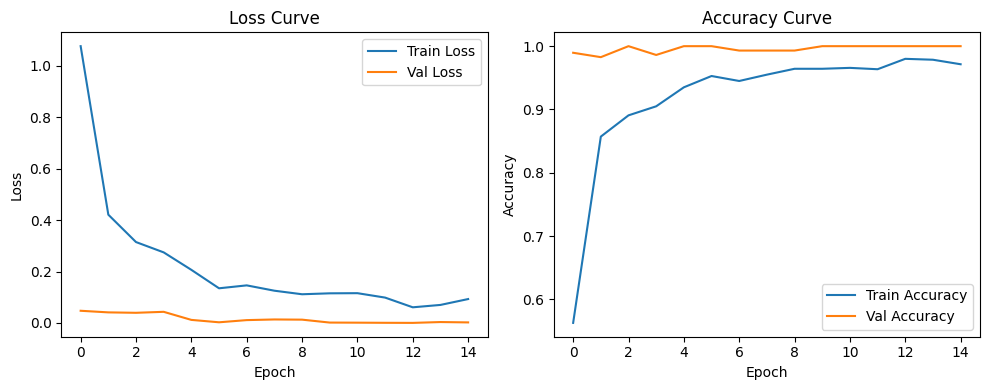

In [13]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15
)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss Curve')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy Curve')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

model.save("mudra_model.keras")

# **Questions**
Did your model show underfitting or overfitting? Support your answer using
the learning curves.

# **Answers**
The model is not showing underfitting, but for the last few epochs there is a mild overfitting

# Model evaluation & failure analysis

              precision    recall  f1-score   support

       Musti       1.00      1.00      1.00        59
      Pataka       1.00      1.00      1.00        64
     Sikhara       1.00      1.00      1.00        64
  Simhamukha       1.00      1.00      1.00        62
     Trisula       1.00      1.00      1.00        63

    accuracy                           1.00       312
   macro avg       1.00      1.00      1.00       312
weighted avg       1.00      1.00      1.00       312



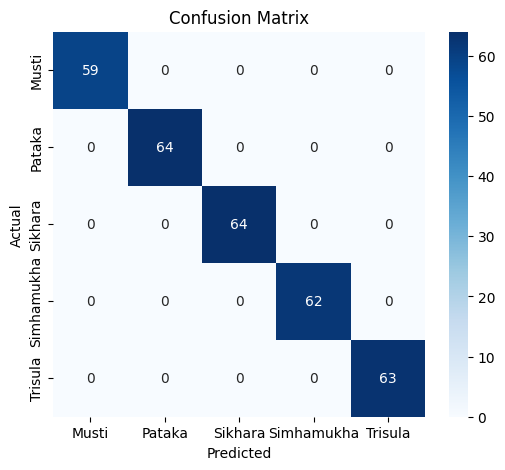

<Figure size 640x480 with 0 Axes>

In [14]:
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

y_true = []
y_pred = []
y_conf = []
all_test_imgs = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    for img, label, pred in zip(images.numpy(), labels.numpy(), preds):
        y_true.append(label)
        y_pred.append(np.argmax(pred))
        y_conf.append(np.max(pred))
        all_test_imgs.append(img.astype("uint8"))

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_conf = np.array(y_conf)

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

plt.tight_layout()
plt.show()

# **Questions**
1. Which mudra pair is most frequently confused? Explain the visual similarity.
2. Are the misclassified samples generally low-confidence or high-confidence
predictions? What does this indicate?


# **Answers**
1. Musti or Pataka are similar because the only difference between them is holding the thumb up or down
2. missclassified samples are most probably because of low confidence.